# 10 · Robustness

**Goal:** check how the system holds up on things a real firm would run into that the synthetic data doesn't fully cover. Each section starts from a question a firm would ask before relying on it.

| Section | A firm would ask | Data |
|---|---|---|
| 3. Real attorney writing | Do our entries look like what it learned from? | real time entries from public bankruptcy fee applications |
| 4. Block billing | Will it split our block-billed entries into the right pieces? | 211 hand-labeled real entries |
| 5. Multi-matter false alarms | Will ordinary entries get flagged as covering two matters? | real entries, each billed to one case |
| 6. Telling a client's matters apart | Can it tell a client's matters apart from how attorneys actually write? | real entries with project-category codes |
| 7. Writing style | Do some attorneys get much more review than others? | VAL, by timekeeper style |
| 8. Retraining | If the models are retrained next month, will the results jump around? | TRAIN subsets, scored on VAL |

**About the real entries.** Bankruptcy fee applications are public, and they list each law firm's time entries for one case. They have no Matter Master and no typed CMID or client fields, so full matching can't be tested on them. The parts that only read the narrative can be, and since this is real attorney writing, it shows how far the synthetic wording is from the real thing.

**Not tested here:** a firm with thousands of matters. There's no realistic way to make up their billing history, so section 6 is the closest real check: telling apart sibling matters at one client.

TEST and the holdout file aren't used.

**Questions**
1. How different is real attorney writing from the synthetic narratives?
2. Do the narrative-only pieces (splitting, the multi-matter text score, past narratives) still work on real writing?
3. Does any writing style get much worse results?
4. How much do results move when the models are retrained on a slightly different history?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sentence_transformers import SentenceTransformer
from sklearn.base import clone
from sklearn.model_selection import PredefinedSplit, cross_val_predict

sys.path.insert(0, "../src")
from clean import normalize
from features import count_parts, past_sim
from rules import answer_key, summarize
from classifier import two_step
from evaluate import headline, slice_table

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../results")
REAL_PATH = Path("../../courtlistener_scrape/data/final/time_entries_clean_balanced.csv")
LABELED_PATH = Path("../../part_2_clean_data/data/final/label_sample_labeled.csv")
SEED = 210
SETTING = "default"

TEXT_FLAG = 0.5            # a narrative text score this high counts as "reads like other work" (section 4)
HISTORY_SHARE = 0.7        # section 5: each client's earliest 70% of entries are billing history, the rest are new
MIN_MATTER_ENTRIES = 10    # section 5: a project category needs this many entries to count as a matter
RETRAIN_SHARE = 0.9        # section 7: each retrain sees a random 90% of TRAIN entries
RETRAIN_DRAWS = 5

# Step 2, same as notebook 04
TARGET = 0.97
ACTION_GB_GRID = {"n_estimators": [50, 100, 200], "num_leaves": [4, 7, 31], "min_child_samples": [20, 50, 100]}
ACTION_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995],
    "no_match_min": [0.3, 0.5, 0.7, 0.9, 0.95],
}
MULTI_GRID = np.round(np.arange(0.05, 0.95, 0.05), 2)
MULTI_BETA = 2
CORRECT_TYPED_CMID = True
ROBUST_SHARE = 0.9

SHOW = ["decided_precision", "straight_through", "review_share", "silent_errors", "matter_accuracy"]

## 2. Load data

- **Synthetic:** notebook 02's pairs table, notebook 00's entries (for the raw narratives), and notebook 04's saved models and VAL decisions.
- **Real entries:** attorney time entries from public bankruptcy fee applications (`courtlistener_scrape`), capped per case. Each one is billed to one case.
- **Hand-labeled real entries:** 240 real entries labeled for narrative quality and block billing (`part_2_clean_data`). Entries labeled `JUNK` are parse errors and are left out.

In [3]:
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
config_04 = json.loads((RESULTS_DIR / "04_config.json").read_text())
models = joblib.load(RESULTS_DIR / "04_model.joblib")
decisions = pd.read_csv(RESULTS_DIR / "04_decisions.csv", low_memory=False)
answers = answer_key(pairs)

entries = pairs.drop_duplicates("entry_id").merge(pd.read_parquet(RESULTS_DIR / "00_entries.parquet")[["entry_id", "narrative"]],
                                                  on="entry_id")
val_entries = entries[entries["split"] == "VAL"]
val_decisions = decisions[(decisions["split"] == "VAL") & (decisions["method"] == f"classifier ({SETTING})")]

real = pd.read_csv(REAL_PATH)
real["narrative_norm"] = real["Narrative"].map(lambda t: normalize(t, drop_suffixes=False))
real["date"] = pd.to_datetime(real["Date"], errors="coerce")
labeled = pd.read_csv(LABELED_PATH)
labeled = labeled[labeled["quality_label"] != "JUNK"].reset_index(drop=True)

assert real["Narrative"].notna().all()
assert labeled["block_billed"].isin(["Y", "N"]).all()
assert len(val_decisions) == val_entries["entry_id"].nunique()
print(f"Synthetic: {len(entries):,} entries | real: {len(real):,} entries from {real['SOURCE: Case'].nunique()} cases "
      f"and {real['SOURCE: Firm'].nunique()} firms | hand-labeled: {len(labeled)}")

Synthetic: 4,000 entries | real: 22,270 entries from 8 cases and 115 firms | hand-labeled: 211


## 3. Real attorney writing

**A firm would ask:** do our attorneys' entries look like what the system learned from?

Three quick comparisons:
- **Length** in words
- **Pieces of work** per narrative (`count_parts`, notebook 02)
- **Known words:** share of each narrative's words that the multi-matter text model saw in training. Words it never saw can't push its score either way.

In [4]:
vocab = set(models["text_model"].named_steps["tfidfvectorizer"].vocabulary_)


def known_share(text):
    words = text.split()
    return np.mean([w in vocab for w in words]) if words else np.nan


real["n_parts"] = real["Narrative"].map(count_parts)
compare = pd.DataFrame({
    name: {"entries": len(df), "median words": df["narrative_norm"].str.split().str.len().median(),
           "longest 10% (words)": df["narrative_norm"].str.split().str.len().quantile(0.9),
           "2+ pieces of work": (df["n_parts"] > 1).mean(), "known words": df["narrative_norm"].map(known_share).mean()}
    for name, df in [("synthetic", entries), ("real", real)]}).T
compare.round(3)

,entries,median words,longest 10% (words),2+ pieces of work,known words
synthetic,4000.0,10.0,25.0,0.449,0.915
real,22270.0,13.0,40.0,0.384,0.528


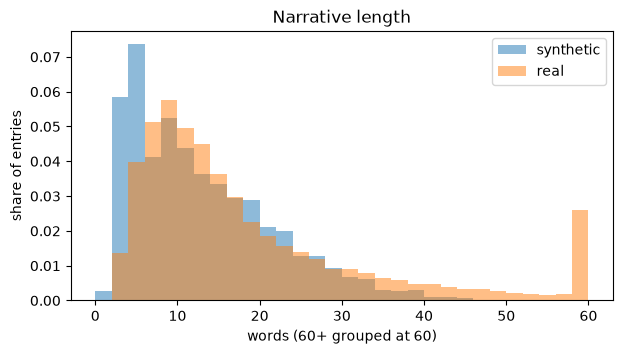

,SOURCE: Case,Narrative
1822,BlockFi Inc.,ATTEND TO CREDITOR INQUIRIES
19334,Sears Holdings Corp.,PREPARE FOR AND ATTEND WEIL/M-III CONFERENCE C...
18778,Sears Holdings Corp.,Correspondence and telephone conf with Milbank...
3145,Celsius Network LLC,Review retention papers (.7); consider issues ...
6557,FTX Trading Ltd.,Revise non-reliance letter.
6473,FTX Trading Ltd.,Prepare venture book memo (1.0).


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.arange(0, 62, 2)
for name, df in [("synthetic", entries), ("real", real)]:
    ax.hist(df["narrative_norm"].str.split().str.len().clip(upper=60), bins=bins, density=True, alpha=0.5, label=name)
ax.set(title="Narrative length", xlabel="words (60+ grouped at 60)", ylabel="share of entries")
ax.legend()
plt.show()

real.sample(6, random_state=SEED)[["SOURCE: Case", "Narrative"]]

- **Real narratives run longer:** median 13 words vs. 10, and the longest 10% run 40+ words vs. 25.
- **About as many cover several pieces of work** (38% vs. 45%).
- **The big gap is vocabulary.** Only about half of real words (53%) are words the text model saw in training, vs. 92% for synthetic narratives. Real attorneys write case names, parties, and shorthand the synthetic phrase bank never used.
- **So the wording-based clues will be weaker on real entries** until the models are retrained on a firm's own history.

## 4. Block billing

**A firm would ask:** will it split our block-billed entries into the right pieces?

Splitting matters for the multi-matter suggestion: each piece of work is matched on its own so a reviewer can see which piece goes where. The 211 hand-labeled real entries say whether each one is block billed (several tasks in one entry). Here `count_parts` says an entry is block billed when it finds two or more pieces.

In [6]:
labeled["n_parts"] = labeled["narrative"].map(count_parts)
found = labeled["n_parts"] > 1
is_block = labeled["block_billed"] == "Y"
print(f"Block billed: {is_block.sum()} of {len(labeled)} | found: {found.sum()} | "
      f"precision {(found & is_block).sum() / found.sum():.2f} | recall {(found & is_block).sum() / is_block.sum():.2f}")
pd.crosstab(is_block.map({True: "block billed", False: "one task"}), found.map({True: "2+ pieces", False: "1 piece"}))

Block billed: 70 of 211 | found: 84 | precision 0.83 | recall 1.00


n_parts,1 piece,2+ pieces
block_billed,,
block billed,0,70
one task,127,14


In [7]:
cols = ["narrative", "quality_label", "n_parts"]
labeled.loc[found & ~is_block, cols].head(6)

,narrative,quality_label,n_parts
4,ANALYZE SECOND CIRCUIT APPELLATE LEGAL ISSUES ...,GOOD,2
6,Attend counsel pre-call ahead of committee cal...,MISSING_SUBJECT,2
42,Continue to research the demarcation between p...,SPECIFIC,2
52,Review docket and update internal files re rec...,CLERICAL,2
53,Update self-insurance specialist workpapers in...,GOOD,2
77,Call w/ N. Werle (Wilmer) regarding witness. P...,VAGUE,2


- **Every block-billed real entry is split into pieces** (70 of 70).
- **14 one-task entries are split too** (83% of splits are right), mostly one long task written as two sentences. For a split suggestion, that costs a reviewer a second look, not a mistake.
- **Splitting holds up on real writing.**

## 5. Multi-matter false alarms

**A firm would ask:** will ordinary entries get flagged as covering two matters?

Every real entry is billed to one bankruptcy case, so its narrative text score (the "reads like other work" score that feeds step 2) should be low. The comparison is VAL's one-matter and multi-matter entries. The text score isn't the decision on its own, but it's the clue that does most of the work for multi-matter calls (notebook 04).

In [8]:
text_model = models["text_model"]
is_multi = val_entries["key_secondary_cmid"].notna()
one_matter = val_entries[~is_multi & (val_entries["key_true_cmid"] != "NONE")]
real["text_score"] = text_model.predict_proba(real["narrative_norm"])[:, 1]
category_label = real["narrative_norm"].str.contains("other contested matters")

groups = {"synthetic, one matter": text_model.predict_proba(one_matter["narrative_norm"])[:, 1],
          "synthetic, multi-matter": text_model.predict_proba(val_entries.loc[is_multi, "narrative_norm"])[:, 1],
          "real, one case": real["text_score"].to_numpy(),
          "real, without category labels": real.loc[~category_label, "text_score"].to_numpy()}
pd.DataFrame({name: {"entries": len(s), "average score": s.mean(), f"score {TEXT_FLAG}+": (s >= TEXT_FLAG).mean()}
              for name, s in groups.items()}).T.round(3)

,entries,average score,score 0.5+
"synthetic, one matter",527.0,0.027,0.002
"synthetic, multi-matter",37.0,0.322,0.297
"real, one case",22270.0,0.041,0.014
"real, without category labels",22171.0,0.039,0.012


In [9]:
with pd.option_context("display.max_colwidth", 120):
    display(real.sort_values("text_score", ascending=False)[["Narrative", "text_score"]].head(10).round(3))

,Narrative,text_score
11974,- Other Contested Matters (excluding assumption / rejection motions) Reviewing LTL petition for rehearing.,0.998
21420,Other Contested Matters Review adversary dockets for,0.991
22172,Other Contested Matters Procedural analysis re SDNY appeal.,0.987
2362,"Review articles re BlockFi, FTX and other crypto cases.",0.987
3763,Call with E. Scott re Prime Trust service and other issues.,0.984
17366,- Case Administration Discus confirmation and other case issues with T. Bielli We appreciate your business,0.983
14600,"Summarize other parties' reply briefs. Call with S. Goldman, K. Kriebs; B. Schneider and N. Karl",0.982
11995,- Other Contested Matters (excluding assumption / rejection motions) Email communication with TCC representatives re...,0.981
7573,Search database for document re: investigations workstream.,0.980
9529,JB Mongon transcript re: excerpts for PI hearing,0.980


- **Real one-case entries rarely read like other work:** 1.4% score 0.5 or more, vs. 0.2% of synthetic one-matter entries and 30% of synthetic multi-matter entries.
- **That's about 7 times the synthetic false-alarm rate, but still low.**
- **The top false alarms use "other" for ordinary work** ("other issues", "other parties", "other crypto cases"), plus a few category labels left over from the scrape. Dropping those labels barely changes the rate (1.2%).
- **The text model leans on the word "other",** so on real data it needs retraining on the firm's own multi-matter entries.

## 6. Telling a client's matters apart

**A firm would ask:** can it tell a client's matters apart from how attorneys actually write?

The hardest silent errors in notebook 06 are sibling matters: the right client, but the wrong matter. Past narratives (notebook 02) are the clue built for this. Here they're tested on real writing.

**Real sibling matters.** Bankruptcy firms usually bill each project category (case administration, fee applications, plan and disclosure statement, and so on) as its own matter, and some fee applications tag each entry with its category code. So for each firm and case:
- **Matters:** project categories with at least `MIN_MATTER_ENTRIES` entries (one category code per entry)
- **Billing history:** the earliest 70% of entries by date
- **New entries:** the rest, each compared with past narratives of every matter at that client (`past_sim`, average of the 3 closest)

**Synthetic comparison:** VAL entries, comparing `past_narrative_sim` across the true client's matters only.

Both are compared with a simple guess: the client's most-billed matter in history.

In [10]:
encoder = SentenceTransformer(feature_config["embedding_model"])

codes = real["SOURCE: Task Codes"].fillna("").str.split(",")
real["category"] = codes.map(lambda c: [x for x in c if x.startswith("B")]).map(lambda b: b[0] if len(b) == 1 else None)
real["client"] = real["SOURCE: Case"] + " | " + real["SOURCE: Firm"]
tagged = real[real["category"].notna() & real["date"].notna() & (real["narrative_norm"] != "")]
counts = tagged.groupby(["client", "category"]).size()
tagged = tagged.merge(counts[counts >= MIN_MATTER_ENTRIES].reset_index()[["client", "category"]])
tagged = tagged.sort_values(["client", "date"]).reset_index(drop=True)
vecs = encoder.encode(tagged["narrative_norm"].tolist(), normalize_embeddings=True)

rows = []
for client, g in tagged.groupby("client"):
    cut = g["date"].quantile(HISTORY_SHARE)
    past, new = g[g["date"] <= cut], g[g["date"] > cut]
    matters = [m for m in g["category"].unique() if (past["category"] == m).sum() >= 3]
    new = new[new["category"].isin(matters)]
    if len(matters) < 2 or new.empty:
        continue
    past = past[past["category"].isin(matters)]
    sims = past_sim(vecs[new.index], np.full(len(new), np.nan), vecs[past.index], np.zeros(len(past)),
                    past["category"].to_numpy(), matters)
    rows.append(pd.DataFrame({"client": client, "matters": len(matters), "narrative_right": sims.idxmax(axis=1).to_numpy() == new["category"].to_numpy(),
                              "most_billed_right": new["category"].to_numpy() == past["category"].value_counts().idxmax()}))
real_sib = pd.concat(rows, ignore_index=True)
print(f"Real: {len(real_sib)} new entries | {real_sib['client'].nunique()} firm-case pairs with 2+ matters")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Real: 640 new entries | 11 firm-case pairs with 2+ matters


In [11]:
mm = pd.read_excel(DATA_PATH, sheet_name="Matter Master", dtype=str).set_index("CMID")["Client"]
val_pairs = pairs[(pairs["split"] == "VAL") & pairs["entry_id"].isin(one_matter["entry_id"])].copy()
val_pairs["matter_client"] = val_pairs["cmid"].map(mm)
true_client = val_pairs[val_pairs["is_true_matter"] == 1].set_index("entry_id")["matter_client"]
siblings = val_pairs[val_pairs["matter_client"] == val_pairs["entry_id"].map(true_client)].copy()
n_matters = siblings.groupby("entry_id").size()
siblings = siblings[siblings["entry_id"].map(n_matters) >= 2]
billed = entries[(entries["split"] == "TRAIN") & (entries["key_true_cmid"] != "NONE")]["key_true_cmid"].value_counts()
siblings["past_entries"] = siblings["cmid"].map(billed).fillna(0)

by_narrative = siblings.loc[siblings.groupby("entry_id")["past_narrative_sim"].idxmax()]
by_billed = siblings.loc[siblings.groupby("entry_id")["past_entries"].idxmax()]
sibling_table = pd.DataFrame({
    "real": {"new entries": len(real_sib), "matters per client": real_sib["matters"].mean(), "random guess": (1 / real_sib["matters"]).mean(),
             "most-billed matter": real_sib["most_billed_right"].mean(), "past narratives": real_sib["narrative_right"].mean()},
    "synthetic (VAL)": {"new entries": len(by_narrative), "matters per client": n_matters[n_matters >= 2].mean(),
                        "random guess": (1 / n_matters[n_matters >= 2]).mean(), "most-billed matter": by_billed["is_true_matter"].mean(),
                        "past narratives": by_narrative["is_true_matter"].mean()}}).T
sibling_table.round(3)

,new entries,matters per client,random guess,most-billed matter,past narratives
real,640.0,4.062,0.306,0.680,0.734
synthetic (VAL),527.0,3.495,0.314,0.769,0.875


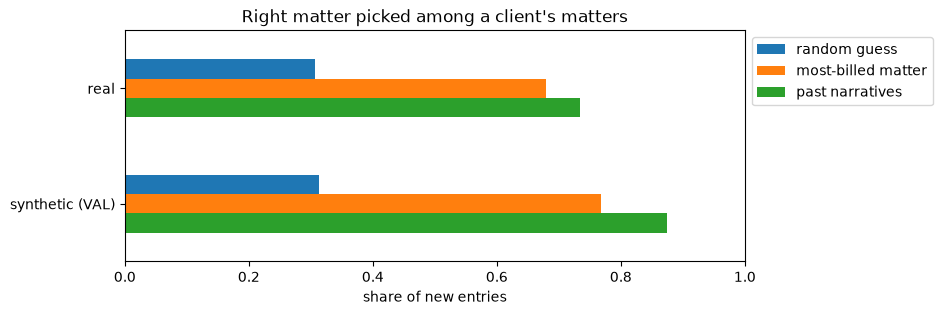

,entries,matters,past_narratives,most_billed
client,,,,
BlockFi Inc. | Daniel Stolz on behalf of Genova Burns LLC,153,4,0.87,0.87
BlockFi Inc. | Donald W Clarke on behalf of Genova Burns LLC,69,5,0.68,0.41
BlockFi Inc. | Genova Burns LLC,105,5,0.55,0.48
FTX Trading Ltd. | Eversheds Sutherland,74,8,0.30,0.22
LTL Management LLC | Daniel Stolz on behalf of Anderson Kill PC,25,2,0.96,0.72
LTL Management LLC | Daniel Stolz on behalf of Bailey & Glasser LLP,13,2,1.00,0.85
LTL Management LLC | Daniel Stolz on behalf of Genova Burns LLC,129,2,0.94,0.94
LTL Management LLC | Daniel Stolz on behalf of Massey & Gail LLP,10,2,0.90,0.90
LTL Management LLC | Paul R,29,2,0.86,0.76


In [12]:
ax = sibling_table[["random guess", "most-billed matter", "past narratives"]].plot.barh(figsize=(8, 3), xlim=(0, 1))
ax.set(title="Right matter picked among a client's matters", xlabel="share of new entries")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.invert_yaxis()
plt.show()

real_sib.groupby("client").agg(entries=("narrative_right", "size"), matters=("matters", "first"),
                               past_narratives=("narrative_right", "mean"), most_billed=("most_billed_right", "mean")).round(2)

- **Past narratives still beat a guess on real writing:** they pick the right matter for 73% of new entries, vs. 31% for a random guess and 68% for always picking the client's most-billed matter.
- **But the edge shrinks by about half:** 5 points over the most-billed matter on real entries, vs. 11 points on synthetic ones (87.5% vs. 77%).
- **It depends on the client:** 86% to 100% where there are a few distinct categories, down to 30% at the client with 8 categories.
- **This is roughly the drop to expect from the wording-based clues on real entries.** CMID, client, dates, and timekeeper history don't depend on wording, so they'd carry more of the weight.

## 7. Writing style

**A firm would ask:** do some attorneys get much more review than others?

Every synthetic timekeeper writes in one style (`key_tk_style`), like a real attorney would: full sentences, "attend to" everywhere, lowercase run-ons, heavy shorthand, terse partner notes, all caps, and so on. This is VAL at the default setting, from notebook 04's saved decisions.

In [13]:
by_style = slice_table(val_decisions, "key_tk_style", min_entries=1)[["entries"] + SHOW].sort_values("straight_through")
by_style.round(3)

,entries,decided_precision,straight_through,review_share,silent_errors,matter_accuracy
abbrev_dense,46.0,0.964,0.609,0.217,1.0,0.804
tcw_heavy,84.0,0.945,0.655,0.202,2.0,0.786
allcaps,30.0,0.952,0.700,0.133,1.0,0.800
lowercase_runon,94.0,0.971,0.734,0.149,2.0,0.904
formal_full,146.0,1.000,0.753,0.144,0.0,0.884
attend_to,103.0,0.988,0.777,0.126,1.0,0.913
terse_partner,50.0,0.974,0.780,0.160,1.0,0.860
quarter_hour,48.0,0.975,0.833,0.083,1.0,0.938


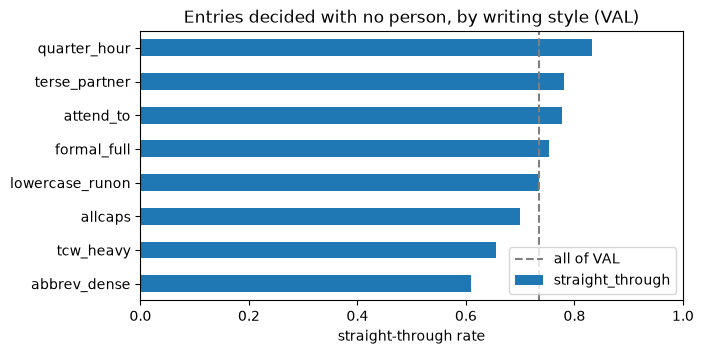

In [14]:
ax = by_style["straight_through"].plot.barh(figsize=(7, 3.5), xlim=(0, 1), title="Entries decided with no person, by writing style (VAL)")
ax.axvline(summarize(val_decisions)["straight_through"], color="gray", linestyle="--", label="all of VAL")
ax.set_xlabel("straight-through rate")
ax.legend()
plt.show()

- **Precision stays between 94.5% and 100% for every style,** with formal full sentences at 100%.
- **Shorthand-heavy writers get less automation:** dense abbreviations (61%) and heavy "tcw" use (66%) vs. 70% to 83% for the rest, with lower matter accuracy (79% to 80%).
- **Heavy shorthand mostly costs review time.** These are small groups (46 to 84 entries), so a few entries move them. Adding a writer's shorthand to the shorthand list is the easy fix.

## 8. Retraining on a different history

**A firm would ask:** if the models are retrained next month, will the results jump around?

A firm retrains on its latest history, so each retrain sees a slightly different set of entries. Here the full system is retrained `RETRAIN_DRAWS` times, each on a random 90% of TRAIN entries (whole entries, keeping their folds), with notebook 04's model settings. Step 2 and the cutoffs are re-picked at the 97% target each time, and VAL is scored once per retrain.

Each retrain takes about a minute.

In [15]:
features = config_04["features"]
pair_model = LGBMClassifier(learning_rate=0.05, random_state=SEED, verbose=-1, **config_04["model_params"])
narratives = entries.set_index("entry_id")["narrative_norm"]
train_pairs = pairs[pairs["split"] == "TRAIN"].reset_index(drop=True)
val_pairs_all = pairs[pairs["split"] == "VAL"].reset_index(drop=True)
train_ids = train_pairs.drop_duplicates("entry_id")["entry_id"]

retrains = []
for draw in range(RETRAIN_DRAWS):
    ids = set(train_ids.sample(frac=RETRAIN_SHARE, random_state=SEED + draw))
    sub = train_pairs[train_pairs["entry_id"].isin(ids)].reset_index(drop=True)
    train_p = cross_val_predict(clone(pair_model), sub[features], sub["is_true_matter"], cv=PredefinedSplit(sub["fold"]),
                                method="predict_proba")[:, 1]
    val_p = clone(pair_model).fit(sub[features], sub["is_true_matter"]).predict_proba(val_pairs_all[features])[:, 1]
    scored, cutoffs, _ = two_step(sub, train_p, val_pairs_all, val_p, answers, narratives, models["text_model"],
                                  feature_config["client_col"], feature_config["matter_col"], TARGET, ACTION_GB_GRID, ACTION_GRID,
                                  MULTI_GRID, MULTI_BETA, CORRECT_TYPED_CMID, SEED, ROBUST_SHARE, refit_text=True)
    result = headline(scored)
    retrains.append({"draw": draw + 1, "auto_min": cutoffs["auto_min"], "no_match_min": cutoffs["no_match_min"],
                     "ci_low": result["ci_low"], **{k: result[k] for k in SHOW}})
retrains = pd.DataFrame(retrains).set_index("draw")
full = {k: headline(val_decisions)[k] for k in SHOW}
retrains.round(3)

,auto_min,no_match_min,ci_low,decided_precision,straight_through,review_share,silent_errors,matter_accuracy
draw,,,,,,,,
1,0.93,0.9,0.974,0.985,0.671,0.203,6,0.864
2,0.93,0.7,0.957,0.971,0.697,0.175,9,0.867
3,0.90,0.7,0.957,0.972,0.725,0.156,10,0.887
4,0.85,0.9,0.959,0.976,0.754,0.141,11,0.865
5,0.90,0.7,0.951,0.968,0.725,0.168,10,0.869


In [16]:
spread = pd.DataFrame({"all of TRAIN (notebook 04)": pd.Series(full), "lowest retrain": retrains[SHOW].min(),
                       "highest retrain": retrains[SHOW].max()})
spread.round(3)

,all of TRAIN (notebook 04),lowest retrain,highest retrain
decided_precision,0.977,0.968,0.985
straight_through,0.735,0.671,0.754
review_share,0.151,0.141,0.203
silent_errors,9.000,6.000,11.000
matter_accuracy,0.870,0.864,0.887


- **Precision stays close to the target:** 96.8% to 98.5% across retrains, with one just under 97%.
- **The cutoffs move, so automation moves more:** `auto_min` lands between 0.85 and 0.93, and 67% to 75% of entries are decided with no person (vs. 74% with all of TRAIN).
- **Silent errors range from 6 to 11.**
- **So a retrain can shift the review workload by several points,** while the margin keeps precision near the target. A firm should check new cutoffs on recent entries before switching.

## 9. Findings

### Results
- **Real attorney writing is longer and uses different words:** the text model knows about half of real words vs. 92% of synthetic ones.
- **The narrative-only pieces still work on real writing, just less well.** Splitting finds every block-billed entry, the multi-matter text score false-alarms on 1.4% of real entries, and past narratives pick the right sibling matter 73% of the time vs. 68% for a simple guess.
- **Shorthand-heavy writers get more review,** not much lower precision.
- **Retraining on a slightly different history** moves automation by several points (67% to 75%) while precision stays near the target (96.8% to 98.5%).

### What this means for real entries
- **Expect the wording-based clues to lose about half their edge.** Past narratives and the multi-matter text score were learned from the synthetic phrase bank.
- **The strongest clues don't depend on wording:** CMID, client, timekeeper history, and dates (notebook 07). They should hold up.
- **Since the cutoffs aim at a precision target,** the likely result on real entries is more review, not more silent errors, once the cutoffs are re-picked on the firm's own data.

### Limitations
- Bankruptcy fee applications are one practice area, and section 6's "matters" are project categories, not a firm's matter list.
- The real entries have no typed fields, so the full pipeline can't run on them.
- A firm with thousands of matters isn't tested.
- 211 labeled entries and 640 sibling-test entries are small samples.

### Next steps
- With a firm's own history, retrain the text model and past narratives first, since they're the pieces most tied to wording.
- Add frequent writers' shorthand to the shorthand list.
- After each retrain, check the new cutoffs on recent entries before switching.